This code achieves two main objectives: (1) Obtain unbiased AUC estimates. (2) Obtain unbiased PsRS OR estimates.  

(1) Obtains unbiased AUC estimates:
* For each disease:
* An elastic net model (α = 0.5) is trained using 80% of participants to generate disease-specific PsRS weights.
* Feature scaling parameters and model coefficients are derived using the training data only.
* The trained PsRS model is applied to the held-out 20% of participants to generate out-of-sample PsRS values.
* 5 multivariate logistic regression models (Base, Genetic, Social, Joint, Interaction) are fit in the training data (80%)
* Models are evaluated (AUC) in the held-out 20% partipants
* Mean and SD of predictive performance are calculated across folds
* Out-of-fold predictions are pooled across all five folds, resulting in one independent out-of-sample prediction per individual for each model
* paired bootstrap comparison of out-of-fold (OOF) AUCs for the genetic and joint models

(2) Obtain unbiased PsRS OR estimates.
* Disease-specific logistic regression models are fit using pooled out-of-fold PsRS values.
* Each individual's PsRS was generated from an elastic net model trained without that individual, preventing overfitting of the PsRS-disease association.
* The resulting PsRS coefficient represents the disease association of an independently generated PsRS.

# Setup

In [51]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("caret")
library(caret)

install.packages("glmnet")
library(glmnet)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



## Load and merge data

In [52]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

#MERGE
demo_sdoh<-merge(demo, ses_data, on="person_id", how="inner")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data<-merge(merged_data, demo_sdoh, on="person_id", how="left")

str(merged_data)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 135557 Columns: 9
── Column specification ────────────────────

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


'data.frame':	104508 obs. of  78 variables:
 $ person_id                        : num  1e+06 1e+06 1e+06 1e+06 1e+06 ...
 $ Asthma_adjusted_score            : num  0.58 -0.495 -0.327 -1.075 -0.468 ...
 $ Afib_adjusted_score              : num  -0.926 0.772 -1.021 0.264 -0.815 ...
 $ BreastC_adjusted_score           : num  1.394 -0.813 0.331 -1.141 0.57 ...
 $ CKD_adjusted_score               : num  0.0337 -0.7092 -0.7648 0.2052 -0.1571 ...
 $ CHD_adjusted_score               : num  -1.4676 -0.8386 0.3516 -0.5479 -0.0629 ...
 $ ProstateC_adjusted_score         : num  0.511 -1.066 -0.815 -1.376 1.367 ...
 $ t1d_adjusted_score               : num  -2.257 -0.544 1.712 1.159 -1.65 ...
 $ t2d_adjusted_score               : num  -0.694 -0.911 2.787 0.928 -0.052 ...
 $ Asthma                           : num  NA NA NA NA NA NA 1 NA NA NA ...
 $ Afib                             : num  1 1 0 NA NA 0 NA NA NA NA ...
 $ BreastC                          : num  NA 0 0 0 NA 0 0 1 NA NA ...
 $ CKD     

In [53]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2<-merged_data$age^2

## Set up lists

In [54]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

disease_name_mapping <- c(
    "Asthma" = "Asthma",
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D",
  "t1d" = "T1D",
    "BreastC" = "Breast\nCancer",
    "ProstateC" = "Prostate\nCancer"
)

selection_terms <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

all_possible_covariates <- c("age", "age2", "record_depth", "visit_frequency", "SexGenderCis_male", "SexGenderSGM")

# Get AUC from five-fold cross validation

## Models

In [55]:
# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  genetic_score <- paste0(disease, "_adjusted_score")
  polysocial_score <- paste0(disease, "_PsRS")
  interaction <- paste0(genetic_score, ":", polysocial_score)

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", base)),
    as.formula(paste(disease, "~", paste(c(base, genetic_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, polysocial_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, polysocial_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, polysocial_score, interaction), collapse = " + ")))
  )
}

## Auc

In [56]:
fit_and_extract_CV <- function(formulas, disease, models, train_data, test_data, fold) {
  map2(formulas, models, ~ {
    # Disease-specific filtering
    disease_specific_filtering <- function(data) {
    filtered_data <- data
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 1)
    }
     filtered_data
  }
    filtered_train_data <- disease_specific_filtering(train_data)
    filtered_test_data <- disease_specific_filtering(test_data)
      
    # Handle missing vars
    vars_in_model <- all.vars(.x)
    filtered_train_data <- filtered_train_data %>% 
      filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    filtered_test_data <- filtered_test_data %>%
      filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit model
    model <- glm(.x, data = filtered_train_data, family = binomial(link = "logit"))

    # Predictions
    preds <- predict(model, newdata = filtered_test_data, type = "response")
    actuals <- filtered_test_data[[disease]]
    ids <- filtered_test_data$person_id

    # AUC + CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)
      auc <- as.numeric(roc_obj$auc)
      auc_ci <- ci.auc(roc_obj)
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)
    }

    list(
      coefficients = tidy(model) %>%
        mutate(Disease = disease,
               Model = .y,
               Fold = fold, 
               AUC = auc,
               AUC_CI_Lower = auc_ci[1],
               AUC_CI_Upper = auc_ci[3]),
      predictions = tibble(
        person_id = ids,
        actual = actuals,
        prediction = preds,
        Disease = disease,
        Model = .y,
        Fold = fold
      )
    )
  })
}


## Elastic net

In [57]:
run_elastic_net <- function(formula_fn, diseases, merged_data) {

  ####---------------------------------------------------------------
  #### 1. Containers
  ####---------------------------------------------------------------
  individual_scores <- list()
  pred_results <- list()
    
  set.seed(123)

  ####---------------------------------------------------------------
  #### 2. Loop over diseases
  ####---------------------------------------------------------------

  for (disease in diseases) {
      
    print(paste0("Starting ", disease))
      
    vars_needed <- unique(c(
    "person_id",
    disease,
    selection_terms,
   all_possible_covariates, 
    paste0("PC_", 1:16),
    paste0(disease, "_adjusted_score")
        ))

    df <- merged_data %>%
        select(all_of(vars_needed)) %>%
        drop_na()

    X <- as.matrix(df %>% select(all_of(selection_terms)))
    y <- as.numeric(df[[disease]])

    penalty_factors <- rep(1, ncol(X))


    ####-----------------------------------------------------------
    #### 3. 5-fold cross-validation
    ####-----------------------------------------------------------

    folds <- createFolds(y, k = 5, list = TRUE)
      
    for (fold in seq_along(folds)) {

        test_idx <- folds[[fold]]
        train_idx <- setdiff(seq_len(nrow(df)), test_idx)

        train_df <- df[train_idx, ]
        test_df  <- df[test_idx, ]

        X_train <- X[train_idx, , drop = FALSE]
        X_test  <- X[test_idx, , drop = FALSE]
        y_train <- y[train_idx]
        y_test  <- y[test_idx]

        # ---- train-only scaling ----
        scale_min <- apply(X_train, 2, min)
        scale_max <- apply(X_train, 2, max)
        scale_rng <- scale_max - scale_min
        scale_rng[scale_rng == 0] <- 1

        X_train <- sweep(sweep(X_train, 2, scale_min, "-"), 2, scale_rng, "/")
        X_test  <- sweep(sweep(X_test,  2, scale_min, "-"), 2, scale_rng, "/")

        cv_fit <- cv.glmnet(
          X_train, y_train,
          alpha = 0.5,
          family = "binomial",
          penalty.factor = penalty_factors
        )

        lambda_best <- cv_fit$lambda.min

        fit <- glmnet(
          X_train, y_train,
          alpha = 0.5,
          lambda = lambda_best,
          family = "binomial",
          penalty.factor = penalty_factors
        )

        # Extract coefficients
        coef_train <- as.vector(coef(fit))
        names(coef_train) <- rownames(coef(fit))

        # Calculate PsRS for held-out fold
        psrs_col <- paste0(disease, "_PsRS")

        train_df[[psrs_col]] <- as.numeric(
          X_train %*% coef_train[-1] + coef_train[1]
        )

        test_df[[psrs_col]] <- as.numeric(
          X_test %*% coef_train[-1] + coef_train[1]
        )

        # Save predictions
        individual_scores[[length(individual_scores) + 1]] <- tibble(
          person_id = df$person_id[test_idx],
          Disease = disease,
          fold = fold,
          PsRS = test_df[[psrs_col]],
          outcome = y_test
        )

  ####---------------------------------------------------------------
  #### 4. Run models
  ####---------------------------------------------------------------
    results <- fit_and_extract_CV(formula_fn(disease), disease, models, train_df, test_df, fold)

    pred_results[[length(pred_results)+1]] <- bind_rows(map(results, "predictions"))

}

  print(paste0("Finished ", disease))
  }
  oof_scores <- bind_rows(individual_scores) 
  pred_results  <- bind_rows(pred_results)

  ####---------------------------------------------------------------
  #### 6. Return
  ####---------------------------------------------------------------

  list(
    oof_scores     = oof_scores,
    pred_results           = pred_results
  )
}

## Run

In [58]:
results_5f_CV<-run_elastic_net(generate_formulas, diseases, merged_data)

[1] "Starting Asthma"


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”

[1] "Finished Asthma"
[1] "Starting Afib"
[1] "Finished Afib"
[1] "Starting BreastC"
[1] "Finished BreastC"
[1] "Starting CKD"
[1] "Finished CKD"
[1] "Starting CHD"
[1] "Finished CHD"
[1] "Starting ProstateC"
[1] "Finished ProstateC"
[1] "Starting t2d"
[1] "Finished t2d"
[1] "Starting t1d"
[1] "Finished t1d"


## Calculate AUC and mean AUC and SD

In [59]:
auc_summary <- results_5f_CV$pred_results %>%
  group_by(Disease, Model, Fold) %>%
  summarise(
    AUC = as.numeric(
      pROC::auc(
        pROC::roc(actual, prediction, quiet = TRUE)
      )
    ),
    .groups = "drop"
  ) %>%
  group_by(Disease, Model) %>%
  summarise(
    mean_AUC = mean(AUC),
    sd_AUC = sd(AUC),
    .groups = "drop"
  )

# Map names
auc_plot_data <- auc_summary  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )

write_excel_csv(auc_plot_data, file.path(output_dir, "auc_joint_model_plot_data.csv"))

# Use OOF Scores to get PsRS coefficients

## Prepare data with OOF scores

In [60]:
#Z-score normalize for comparison 
oof_scores <- results_5f_CV$oof_scores %>%
  group_by(Disease) %>%
  mutate(
    PsRS = as.numeric(scale(PsRS))
  ) %>%
  ungroup()

oof_scores_wide <- oof_scores %>%
  mutate(PsRS_name = paste0(Disease, "_PsRS")) %>%
  select(person_id, PsRS_name, PsRS) %>%
  pivot_wider(
    names_from = PsRS_name,
    values_from = PsRS
  )

#verify that each disease PsRS has one value per person
results_5f_CV$oof_scores %>%
  count(person_id, Disease) %>%
  filter(n > 1)

merged_data_PsRS <- merge(merged_data, oof_scores_wide, by="person_id")
write_excel_csv(oof_scores_wide, file.path(output_dir, "individual_PsRS_OOF.csv"))

person_id,Disease,n
<dbl>,<chr>,<int>


## Function to extract coefficients

In [61]:
fit_and_extract_oof <- function(formulas, disease, models, data) {

  map2(formulas, models, ~ {

    disease_specific_filtering <- function(data) {

      filtered_data <- data

      if (disease %in% c("CKD", "t1d")) {
        filtered_data <- filtered_data %>% 
          filter(SexGenderSGM == 0)
      }

      if (disease == "BreastC") {
        filtered_data <- filtered_data %>% 
          filter(SexGenderCis_male == 0)
      }

      if (disease == "ProstateC") {
        filtered_data <- filtered_data %>% 
          filter(SexGenderCis_male == 1)
      }

      filtered_data
    }


    filtered_data <- disease_specific_filtering(data)

    vars_in_model <- all.vars(.x)

    filtered_data <- filtered_data %>%
      filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    model <- glm(
      .x,
      data = filtered_data,
      family = binomial(link = "logit")
    )


    tidy(model) %>%
      mutate(
        Disease = disease,
        Model = .y,
        OR = exp(estimate)
      )

  })
}

## Run

In [62]:
results <- tibble(disease = diseases) %>%
  rowwise() %>%
  mutate(model_results = list(
    fit_and_extract_oof(
      generate_formulas(disease),
      disease,
      models,
      merged_data_PsRS
    )
  )) %>%
  ungroup()


# All coefficients
coeff_results <- results %>%
  mutate(
    coeffs = map(model_results, ~ bind_rows(.x))
  ) %>%
  select(disease, coeffs) %>%
  unnest(coeffs)

Warning message:
“There were 5 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(...)`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 4 remaining warnings.”


## Save coefficients

In [63]:
coeff_results_subset <- coeff_results |>
  filter(str_detect(term, "_adjusted_score$|PsRS|:")) |>
  select(Model, Disease, term, estimate, std.error, statistic, p.value) |>
    mutate(OR = exp(estimate),
          OR_Lower = exp(estimate - 1.96 * std.error),
          OR_Upper = exp(estimate + 1.96 * std.error))

head(coeff_results_subset, 5)

write_excel_csv(coeff_results_subset, file.path(output_dir, "joint_model_coeff_results.csv"))

Model,Disease,term,estimate,std.error,statistic,p.value,OR,OR_Lower,OR_Upper
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Genetic,Asthma,Asthma_adjusted_score,0.2258886,0.01416618,15.94563,3.055665e-57,1.253436,1.219112,1.288726
Social,Asthma,Asthma_PsRS,0.3769742,0.01488456,25.32653,1.630403e-141,1.457867,1.415950,1.501025
Joint,Asthma,Asthma_adjusted_score,0.2327036,0.01436869,16.19519,5.453284e-59,1.262007,1.226962,1.298054
Joint,Asthma,Asthma_PsRS,0.3813774,0.01497052,25.47522,3.710777e-143,1.464300,1.421958,1.507902
Interaction,Asthma,Asthma_adjusted_score,0.2334449,0.01440894,16.20139,4.929695e-59,1.262943,1.227775,1.299119


# Prepare AUC Plot 

In [64]:
model_colors <- c(
  "Base"    = "#E69F00", # orange
  "Genetic" = "#0072B2", # blue
  "Social"  = "#009E73", # bluish green
  "Joint"   = "#D55E00", # vermillion
  "Interaction" = "grey"
)

facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

auc_plot_data <- auc_plot_data %>%
  mutate(
    Model = factor(Model, c("Base", "Social", "Genetic",
                                    "Joint", "Interaction")),
    Disease = factor(Disease, facet_order)
  )

# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Disease, y = mean_AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.7), size = 3.5) +  # Points for AUC
  geom_errorbar(aes(ymin = mean_AUC - sd_AUC, ymax = mean_AUC + sd_AUC), 
                position = position_dodge(width = 0.7), width = 0.4) +  # Error bars for 95% CI
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = " ",
    y = "AUC"
  ) +
  theme_minimal(base_size = 24) +
 theme(legend.position = "top") + 
 scale_color_manual(values = model_colors) + 
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black")
  ) +
  geom_vline(xintercept = seq(1.5, length(unique(auc_plot_data$Disease)) - 0.5, 1),
             color = "darkgrey")

write_excel_csv(auc_plot_data, file.path(output_dir, "auc_joint_model_plot_data.csv"))

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


# Bootstrap Test of Significance using pooled out-of-sample

In [65]:
fast_auc <- function(actual, prediction) {
  keep <- !is.na(actual) & !is.na(prediction)
  actual <- actual[keep]
  prediction <- prediction[keep]

  classes <- sort(unique(actual))
  if (length(classes) != 2) {
    return(NA_real_)
  }

  y <- as.integer(actual == classes[2])
  n_pos <- sum(y == 1, na.rm = TRUE)
  n_neg <- sum(y == 0, na.rm = TRUE)

  if (n_pos == 0 || n_neg == 0) {
    return(NA_real_)
  }

  ranks <- rank(prediction, ties.method = "average", na.last = "keep")
  (sum(ranks[y == 1], na.rm = TRUE) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
}

compare_models_oof <- function(df, model1, model2, n_boot = 2000) {

  comparison_df <- df %>%
    filter(Model %in% c(model1, model2)) %>%
    select(person_id, actual, Model, prediction) %>%
    tidyr::pivot_wider(names_from = Model, values_from = prediction) %>%
    arrange(person_id) %>%
    tidyr::drop_na(all_of(c(model1, model2)))

  stopifnot(all(c(model1, model2) %in% names(comparison_df)))
  stopifnot(n_distinct(comparison_df$actual) == 2)

  actual <- comparison_df$actual
  pred1 <- comparison_df[[model1]]
  pred2 <- comparison_df[[model2]]

  auc1 <- fast_auc(actual, pred1)
  auc2 <- fast_auc(actual, pred2)
  delta_auc <- auc2 - auc1

  boot_delta_auc <- replicate(n_boot, {
    boot_idx <- sample.int(nrow(comparison_df), size = nrow(comparison_df), replace = TRUE)
    fast_auc(actual[boot_idx], pred2[boot_idx]) - fast_auc(actual[boot_idx], pred1[boot_idx])
  })

  boot_delta_auc <- boot_delta_auc[!is.na(boot_delta_auc)]
  centered_boot_delta_auc <- boot_delta_auc - delta_auc
  bootstrap_extreme_n <- sum(abs(centered_boot_delta_auc) >= abs(delta_auc))
  p_value_min <- 1 / (length(centered_boot_delta_auc) + 1)
  p_value <- (bootstrap_extreme_n + 1) / (length(centered_boot_delta_auc) + 1)
  p_value_label <- ifelse(
    bootstrap_extreme_n == 0,
    paste0("<", signif(p_value_min, 3)),
    as.character(signif(p_value, 3))
  )

  tibble(
    Model1 = model1,
    Model2 = model2,
    AUC1 = auc1,
    AUC2 = auc2,
    delta_AUC = delta_auc,
    p_value = p_value,
    p_value_label = p_value_label,
    p_value_min = p_value_min,
    bootstrap_extreme_n = bootstrap_extreme_n,
    bootstrap_n = length(boot_delta_auc),
    bootstrap_ci_low = unname(quantile(boot_delta_auc, 0.025)),
    bootstrap_ci_high = unname(quantile(boot_delta_auc, 0.975))
  )
}

models <- c("Base", "Genetic", "Social", "Joint", "Interaction")
auc_model_comparisons <- list(
  c("Genetic", "Joint")
)

auc_bootstrap_n <- 5000
set.seed(12345)

auc_tests <- results_5f_CV$pred_results %>%
  group_by(Disease) %>%
  group_modify(~ {

    disease_df <- .x

    map_dfr(
      auc_model_comparisons,
      function(comp) {
        compare_models_oof(
          disease_df,
          comp[1],
          comp[2],
          n_boot = auc_bootstrap_n
        )
      }
    )
  })

In [ ]:
nrow(auc_tests)
0.05 / nrow(auc_tests)

auc_comparisons <- auc_tests %>%
  mutate(
    bonf_p = 0.05 / nrow(auc_tests),      # Bonferroni threshold
    p_value_bonf = p_value * nrow(auc_tests), # adjusted p-value
    p_value_bonf = ifelse(p_value_bonf > 1, 1, p_value_bonf), # cap at 1
    significant = p_value = p_value_min            # TRUE/FALSE flag
    )

# Map names
auc_comparisons <- auc_comparisons  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )


write_excel_csv(auc_comparisons, file.path(output_dir, "auc_comparisons_sdoh_joint_modeling.csv"))
nrow(auc_comparisons)

In [ ]:
auc_comparisons |>
  dplyr::filter(Model1 == "Genetic", Model2 == "Joint") |>
  dplyr::mutate(AUC_diff = AUC2 - AUC1) |>
  arrange(AUC_diff)

In [ ]:
auc_comparisons

# Plot 

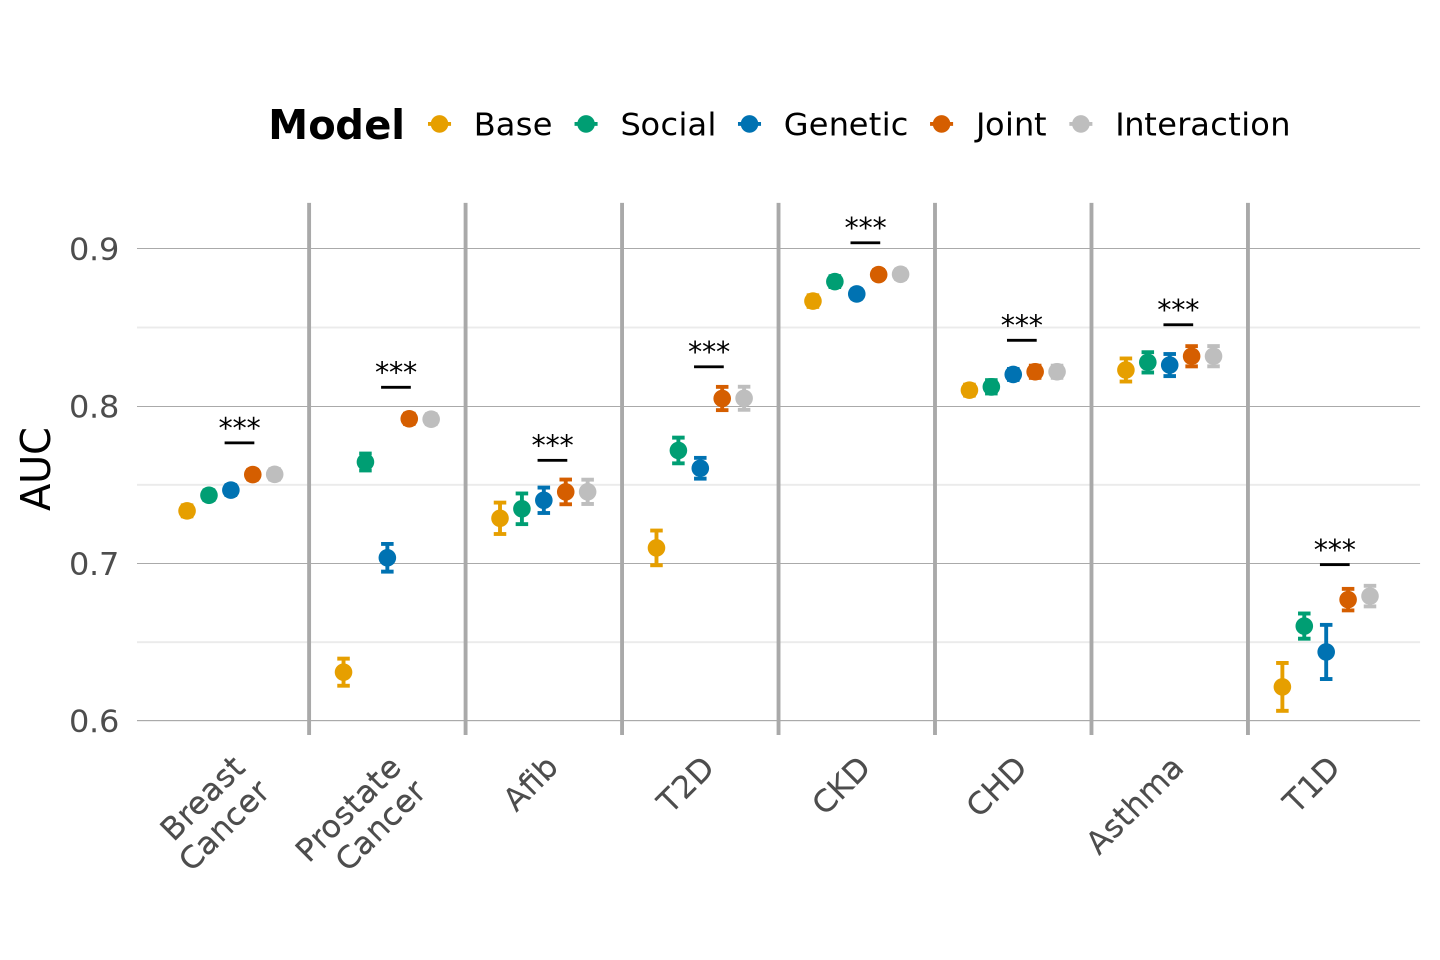

In [38]:
facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)


auc_comparisons <- auc_comparisons %>% 
 mutate(Disease = factor(Disease, facet_order))

auc_plot_data <- auc_plot_data |>
    mutate(Disease = factor(Disease, facet_order))

gen_joint_lines <- auc_comparisons %>%
  filter(
    (Model1 == "Genetic" & Model2 == "Joint") |
    (Model1 == "Joint" & Model2 == "Genetic")
  ) %>%
  left_join(
    auc_plot_data %>%
      group_by(Disease) %>%
      summarize(y = max(mean_AUC, na.rm = TRUE)),
    by = "Disease"
  ) %>%
  mutate(
    Disease = factor(Disease, levels = facet_order),
    y = y + 0.02, #vertical offset
    x_start = as.numeric(Disease) - 0.04,
    x_end = as.numeric(Disease) + 0.15,
    significance_label = if_else(significant, "***", "")
  )

auc_plot <- auc_plot +
  geom_segment(
    data = gen_joint_lines,
    aes(x = x_start, xend = x_end, y = y, yend = y),
    inherit.aes = FALSE,
    linewidth = 0.8
  ) +
  geom_text(
    data = gen_joint_lines,
    aes(x = (x_start + x_end) / 2, y = y + 0.01, label = significance_label),
    inherit.aes = FALSE,
    size = 6
  )

# Set plot size for Jupyter Notebook
options(repr.plot.width = 12, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci.png", plot = auc_plot, width = 12, height = 8, dpi = 300)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


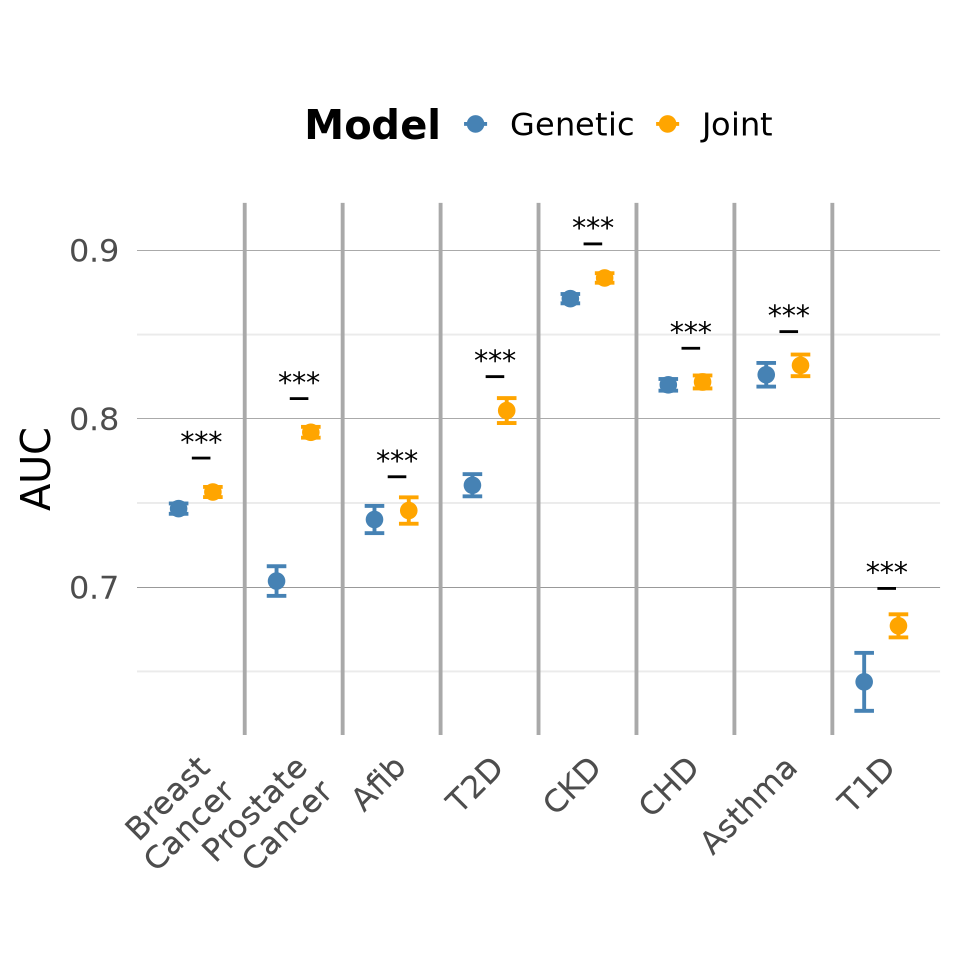

In [39]:
options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height


auc_plot_data_mini <- auc_plot_data[auc_plot_data$Model %in% c("Genetic", "Joint"), ]

auc_plot_data_mini <- auc_plot_data_mini %>%
  mutate(
    Model = factor(Model, c( "Genetic", "Joint")),
    Disease = factor(Disease, facet_order)
  )

model_colors_mini <- c(
  "Genetic" = "steelblue",
  "Joint"   = "orange"
)


# Create the plot
auc_plot_mini <- ggplot(auc_plot_data_mini, aes(x = Disease, y = mean_AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.7), size = 3.5) +  # Points for AUC
  geom_errorbar(aes(ymin = mean_AUC - sd_AUC, ymax = mean_AUC + sd_AUC), 
                position = position_dodge(width = 0.7), width = 0.4) +  # Error bars for 95% CI
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = " ",
    y = "AUC"
  ) +
  theme_minimal(base_size = 24) +
 theme(legend.position = "top") + 
 scale_color_manual(values = model_colors_mini) + 
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black")
  ) +
  geom_vline(xintercept = seq(1.5, length(unique(auc_plot_data$Disease)) - 0.5, 1),
             color = "darkgrey")

auc_plot_mini +
  geom_segment(
    data = gen_joint_lines,
    aes(x = x_start, xend = x_end, y = y, yend = y),
    inherit.aes = FALSE,
    linewidth = 0.8
  ) +
  geom_text(
    data = gen_joint_lines,
    aes(x = (x_start + x_end) / 2, y = y + 0.01, label = significance_label),
    inherit.aes = FALSE,
    size = 6
  )


# RE RUN control for PCs

## Models

In [40]:
# Model labels
models <- c("Base", "Genetic", "Social", "Joint", "Interaction")

# Function to generate formulas for disease-domain pairs
generate_formulas_PCs <- function(disease) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  genetic_score <- paste0(disease, "_adjusted_score")
  polysocial_score <- paste0(disease, "_PsRS")
  interaction <- paste0(genetic_score, ":", polysocial_score)

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", base)),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, paste0("PC_", 1:16)), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, polysocial_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, paste0("PC_", 1:16), polysocial_score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, genetic_score, paste0("PC_", 1:16), polysocial_score, interaction), collapse = " + ")))
 

  )
}


## Get AUC

In [41]:
results_5f_CV_PCs<-run_elastic_net(generate_formulas_PCs, diseases, merged_data)

auc_summary <- results_5f_CV_PCs$pred_results %>%
  group_by(Disease, Model, Fold) %>%
  summarise(
    AUC = as.numeric(
      pROC::auc(
        pROC::roc(actual, prediction, quiet = TRUE)
      )
    ),
    .groups = "drop"
  ) %>%
  group_by(Disease, Model) %>%
  summarise(
    mean_AUC = mean(AUC),
    sd_AUC = sd(AUC),
    .groups = "drop"
  )

# Map names
auc_plot_data <- auc_summary  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )

write_excel_csv(auc_plot_data, file.path(output_dir, "auc_joint_model_plot_data_PCs.csv"))

[1] "Starting Asthma"


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”

[1] "Finished Asthma"
[1] "Starting Afib"
[1] "Finished Afib"
[1] "Starting BreastC"
[1] "Finished BreastC"
[1] "Starting CKD"
[1] "Finished CKD"
[1] "Starting CHD"
[1] "Finished CHD"
[1] "Starting ProstateC"
[1] "Finished ProstateC"
[1] "Starting t2d"
[1] "Finished t2d"
[1] "Starting t1d"
[1] "Finished t1d"


In [48]:
facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "Afib", "T2D",
  "CKD", "CHD", "Asthma", "T1D"
)

auc_plot_data <- auc_plot_data %>%
  mutate(
    Model = factor(Model, c("Base", "Social", "Genetic",
                                    "Joint", "Interaction")),
    Disease = factor(Disease, facet_order)
  )


# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Disease, y = mean_AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.7), size = 3.5) +  # Points for AUC
  geom_errorbar(aes(ymin = mean_AUC - sd_AUC, ymax = mean_AUC + sd_AUC), 
                position = position_dodge(width = 0.7), width = 0.4) +  # Error bars for 95% CI
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = " ",
    y = "AUC"
  ) +
  theme_minimal(base_size = 24) +
 theme(legend.position = "top") + 
 scale_color_manual(values = model_colors) + 
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(size = 0.1, color = "black")
  ) +
  geom_vline(xintercept = seq(1.5, length(unique(auc_plot_data$Disease)) - 0.5, 1),
             color = "darkgrey")


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


## Get coefficients

In [43]:
#Z-score normalize for comparison 
oof_scores <- results_5f_CV_PCs$oof_scores %>%
  group_by(Disease) %>%
  mutate(
    PsRS = as.numeric(scale(PsRS))
  ) %>%
  ungroup()

oof_scores_wide <- oof_scores %>%
  mutate(PsRS_name = paste0(Disease, "_PsRS")) %>%
  select(person_id, PsRS_name, PsRS) %>%
  pivot_wider(
    names_from = PsRS_name,
    values_from = PsRS
  )

#verify that each disease PsRS has one value per person
results_5f_CV$oof_scores %>%
  count(person_id, Disease) %>%
  filter(n > 1)

merged_data_PsRS_PCs <- merge(merged_data, oof_scores_wide, by="person_id")

results <- tibble(disease = diseases) %>%
  rowwise() %>%
  mutate(model_results = list(
    fit_and_extract_oof(
      generate_formulas_PCs(disease),
      disease,
      models,
      merged_data_PsRS
    )
  )) %>%
  ungroup()


# All coefficients
coeff_results <- results %>%
  mutate(
    coeffs = map(model_results, ~ bind_rows(.x))
  ) %>%
  select(disease, coeffs) %>%
  unnest(coeffs)

coeff_results_subset <- coeff_results |>
  filter(str_detect(term, "_adjusted_score$|PsRS|:")) |>
  select(Model, Disease, term, estimate, std.error, statistic, p.value) |>
    mutate(OR = exp(estimate),
          OR_Lower = exp(estimate - 1.96 * std.error),
          OR_Upper = exp(estimate + 1.96 * std.error))

head(coeff_results_subset, 5)

write_excel_csv(coeff_results_subset, file.path(output_dir, "joint_model_coeff_results_adj_PCs.csv"))

person_id,Disease,n
<dbl>,<chr>,<int>


Warning message:
“There were 5 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(...)`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 4 remaining warnings.”


Model,Disease,term,estimate,std.error,statistic,p.value,OR,OR_Lower,OR_Upper
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Genetic,Asthma,Asthma_adjusted_score,0.2245599,0.01423604,15.77404,4.694754e-56,1.251772,1.217327,1.287191
Social,Asthma,Asthma_PsRS,0.3769742,0.01488456,25.32653,1.630403e-141,1.457867,1.415950,1.501025
Joint,Asthma,Asthma_adjusted_score,0.2302556,0.01443177,15.95477,2.639311e-57,1.258922,1.223810,1.295040
Joint,Asthma,Asthma_PsRS,0.3785792,0.01520500,24.89834,7.754572e-137,1.460208,1.417334,1.504380
Interaction,Asthma,Asthma_adjusted_score,0.2310350,0.01447010,15.96637,2.191602e-57,1.259903,1.224673,1.296147


## Bootstrap comparison 

In [44]:
set.seed(12345)

auc_tests <- results_5f_CV_PCs$pred_results %>%
  group_by(Disease) %>%
  group_modify(~ {

    disease_df <- .x

    map_dfr(
      auc_model_comparisons,
      function(comp) {
        compare_models_oof(
          disease_df,
          comp[1],
          comp[2],
          n_boot = auc_bootstrap_n
        )
      }
    )
  })


nrow(auc_tests)
0.05 / nrow(auc_tests)

auc_comparisons <- auc_tests %>%
  mutate(
    bonf_p = 0.05 / nrow(auc_tests),      # Bonferroni threshold
    p_value_bonf = p_value * nrow(auc_tests), # adjusted p-value
    p_value_bonf = ifelse(p_value_bonf > 1, 1, p_value_bonf), # cap at 1
    significant = p_value = p_value_min              # TRUE/FALSE flag
  )

# Map names
auc_comparisons <- auc_comparisons  %>% mutate(Disease = as.character(Disease), 
                                                    Disease = recode(Disease, 
                                                    !!!disease_name_mapping, 
                                                                     .default = Disease) )

write_excel_csv(auc_comparisons, file.path(output_dir, "auc_comparisons_sdoh_joint_modeling_PCs.csv"))

[1] 8

[1] 0.00625

In [46]:
auc_comparisons

Disease,Model1,Model2,AUC1,AUC2,delta_AUC,p_value,p_value_label,p_value_min,bootstrap_extreme_n,bootstrap_n,bootstrap_ci_low,bootstrap_ci_high,bonf_p,p_value_bonf,significant
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
Afib,Genetic,Joint,0.7471947,0.7492667,0.002072011,0.00019996,<2e-04,0.00019996,0,5000,0.0011087009,0.003034400,0.00625,0.00159968,TRUE
Asthma,Genetic,Joint,0.8272863,0.8328792,0.005592875,0.00019996,<2e-04,0.00019996,0,5000,0.0037533633,0.007445471,0.00625,0.00159968,TRUE
Breast Cancer,Genetic,Joint,0.7529057,0.7586209,0.005715239,0.00019996,<2e-04,0.00019996,0,5000,0.0040195351,0.007296042,0.00625,0.00159968,TRUE
CHD,Genetic,Joint,0.8214719,0.8227536,0.001281647,0.00019996,<2e-04,0.00019996,0,5000,0.0008695338,0.001704715,0.00625,0.00159968,TRUE
CKD,Genetic,Joint,0.8883085,0.8928779,0.004569442,0.00019996,<2e-04,0.00019996,0,5000,0.0038073041,0.005337857,0.00625,0.00159968,TRUE
Prostate Cancer,Genetic,Joint,0.7278230,0.8008784,0.073055451,0.00019996,<2e-04,0.00019996,0,5000,0.0653195290,0.080980849,0.00625,0.00159968,TRUE
T1D,Genetic,Joint,0.6672123,0.6822928,0.015080493,0.00099980,0.001,0.00019996,4,5000,0.0061331044,0.024103408,0.00625,0.00799840,TRUE
T2D,Genetic,Joint,0.8006472,0.8177070,0.017059871,0.00019996,<2e-04,0.00019996,0,5000,0.0154472159,0.018634777,0.00625,0.00159968,TRUE


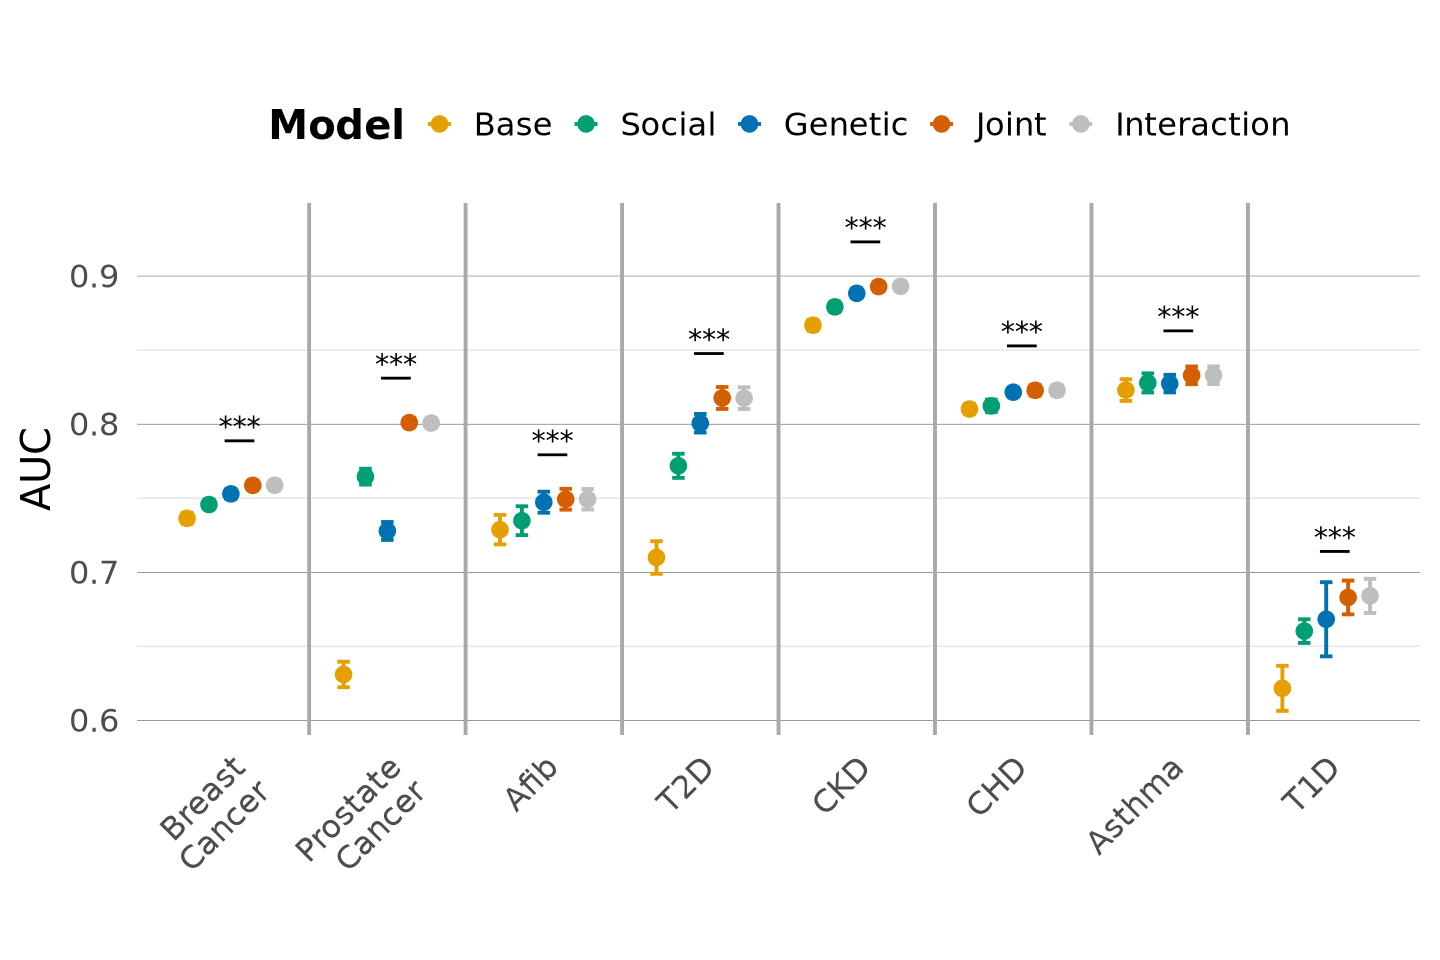

In [49]:
auc_comparisons <- auc_comparisons %>% 
 mutate(
    Disease = factor(Disease, facet_order)
  )

gen_joint_lines <- auc_comparisons %>%
  filter(
    (Model1 == "Genetic" & Model2 == "Joint") |
    (Model1 == "Joint" & Model2 == "Genetic")
  ) %>%
  left_join(
    auc_plot_data %>%
      group_by(Disease) %>%
      summarize(y = max(mean_AUC, na.rm = TRUE)),
    by = "Disease"
  ) %>%
  mutate(
    Disease = factor(Disease, levels = facet_order),
    y = y + 0.03,        # vertical offset above CI
    x_start = as.numeric(Disease) - 0.04,
    x_end   = as.numeric(Disease) + 0.15,
    significance_label = if_else(significant, "***", "")
  )

auc_plot <- auc_plot +
  geom_segment(
    data = gen_joint_lines,
    aes(x = x_start, xend = x_end, y = y, yend = y),
    inherit.aes = FALSE,
    linewidth = 0.8
  ) +
  geom_text(
    data = gen_joint_lines,
    aes(x = (x_start + x_end) / 2, y = y + 0.01, label = significance_label),
    inherit.aes = FALSE,
    size = 6
  )

# Set plot size for Jupyter Notebook
options(repr.plot.width = 12, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci_PCs.png", plot = auc_plot, width = 12, height = 8, dpi = 300)
